# Stage 01 capstone: build and defend two predictive pipelines

## 1. Introduction and learning objectives

Implement regression and binary classification pipelines manually, using deterministic local data. Independently verify gradients before model selection. Fit transforms inside training folds, compare with baselines, select a threshold with validation data, and evaluate once on untouched test observations. A good-looking metric cannot substitute for a valid procedure.

Read the [project instructions](README.md), work on a study branch, and complete the [report template](report-template.md). Every implementation answer is blank. The displayed references form a self-contained project; they never import another notebook's live kernel or a completed package implementation.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 01.P.01 — Pre-register the selection protocol

**Type:** Conceptual · **Answer:** Markdown

Declare dataset seeds, split policy, penalty grid, optimization budget, selection metrics, threshold costs, and the final test procedure. Assign each decision to a partition. Define when you would stop and fix code before accessing test results.

**Expected outcome:** a replayable protocol and separate explain/implement/verify/evaluate claims.

**Your response to Exercise 01.P.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.01**

The test set is not a debugging fixture. Use hand examples and training-only checks for correctness.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.01**

Use data seeds 70/71 and split seed 72, with 180/60/60 rows for train/validation/test. Use five training-only folds, seed 73, grid [0,.01,.1,1], 800 full-batch steps at rate .1, and CV MSE for regression or mean log loss for classification. Fit scaling within each fold, then fit selected models only on all training rows. Select the classifier threshold on validation data using false-positive cost 1 and false-negative cost 2 over [.2,.3,.4,.5,.6,.7,.8]. Freeze all choices before test reporting. Resolve gradient, shape, stability, or convergence failures using verification and training diagnostics first. Do not repair or tune after reading test scores and still call that set untouched.

</details>

## 2. Prerequisites and mathematical foundations

Complete all five Stage 01 chapters. Let A be standardized features, r=Aw+b−y, p=σ(Aw+b), and λ≥0. Use half-MSE plus λ||w||²/2 for regression, and mean binary cross-entropy plus λ||w||²/2 for classification. Bias is unpenalized. Mean data gradients are Aᵀr/n, mean(r), or Aᵀ(p−y)/n, mean(p−y); add λw only to weights.

The transform fitted on a training partition stores its column mean and population standard deviation. Replace a zero standard deviation with one; a constant training column then transforms to zero. Validation/test transforms use that unchanged state. This does not imply that a formerly constant feature will be constant in a new population.

## 3. Theoretical development and worked examples

### Exercise 01.P.02 — Derive both objectives at one snapshot

**Type:** Mathematical · **Answer:** Markdown

Derive both weight/bias gradients, state every shape, and explain why duplicating training rows should not change the objective or gradient at fixed parameters and λ.

**Expected outcome:** two derivations with the mean and penalty scaling explicit.

**Your response to Exercise 01.P.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.02**

For logistic loss, differentiate softplus(z)−yz before applying the affine chain rule.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.02**

For regression, dJ=rᵀ(A dw+db)/n+λwᵀdw, giving dw-gradient Aᵀr/n+λw of shape (d,) and scalar bias gradient mean(r). Logistic dℓ/dz=p−y yields Aᵀ(p−y)/n+λw and mean(p−y). The vectors r,p,y have shape (n,). Duplicating all rows doubles the data sum and n, leaving the mean unchanged; the penalty remains λ||w||²/2. No downstream extra average is allowed.

</details>

### Exercise 01.P.03 — Create a tiny independent oracle

**Type:** Numerical · **Answer:** Markdown

For A=[(1,0),(0,2)], y=(1,0), w=(0,0), b=0, λ=.1, calculate both objectives and gradients. Then explain what nonzero weights add to a finite-difference test.

**Expected outcome:** exact values and a second test point that exercises the penalty derivative.

**Your response to Exercise 01.P.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.03**

At zero logits, probabilities are .5 and cross-entropy is log 2.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.03**

Regression J=.25, gradient w=(−.5,0), gradient b=−.5. Classification J=log 2, gradient w=(−.25,.5), gradient b=0. At w=0 the L2 derivative is zero, so this point cannot expose a missing λw term. Add nonzero weights and bias, n=1 as well as n>1, repeated rows, and finite differences of an independently coded objective.

</details>

## 4. Guided exercises

The supplied data are deterministic examples, not benchmarks claiming general ML performance. Each task has 300 rows and five features. Regression is a noisy affine function; classification draws Bernoulli labels from an affine logit. Feature units differ and two features are correlated. Splits are independent of outcomes; these synthetic iid tasks do not model grouped or temporal deployment.

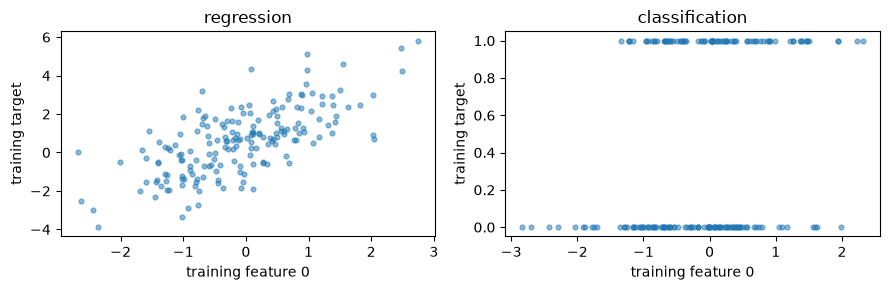

In [2]:
data_sets = {}
split_order = np.random.default_rng(72).permutation(300)
split_ids = {"train": split_order[:180], "validation": split_order[180:240], "test": split_order[240:]}
for task, seed in (("regression", 70), ("classification", 71)):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(300, 5))
    X[:, 1] = .8 * X[:, 0] + .6 * X[:, 1]
    X *= np.array([1., 2., .5, 1., 3.])
    if task == "regression":
        y = X @ np.array([2., -.6, .5, 0., .2]) + .7 + rng.normal(0, .8, 300)
    else:
        logits = X @ np.array([1.3, -.3, .5, 0., .1]) - .3
        y = rng.binomial(1, 1 / (1 + np.exp(-logits))).astype(float)
    data_sets[task] = {part: (X[ids].copy(), y[ids].copy()) for part, ids in split_ids.items()}
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, task in zip(axes, ("regression", "classification")):
    X, y = data_sets[task]["train"]
    ax.scatter(X[:, 0], y, s=12, alpha=.5)
    ax.set(xlabel="training feature 0", ylabel="training target", title=task)
fig.tight_layout(); plt.show()

### Exercise 01.P.04 — Define the baselines and checkpoints

**Type:** Conceptual · **Answer:** Markdown

Specify a deployable baseline for each task and what you will save at the end of each work session. Which performance or verification claims can be established before opening test results?

**Expected outcome:** training-mean and training-prevalence baselines plus resumable artifacts.

**Your response to Exercise 01.P.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.04**

Replayable configuration and verified functions are useful checkpoints even before any model-selection result exists.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.04**

Predict the training mean for regression and training positive fraction for classification, preserving both unchanged on held-out data. Save the protocol/splits first, then verified implementations, then CV score tables and frozen model/transform/threshold configuration, and finally the test report. Derivations, independent numerical correctness, fold isolation, optimizer diagnostics, and validation decisions can all be established before test evaluation. These checkpoints permit two-hour study sessions without requiring a long-running job.

</details>

## 5. Implementation challenges

### Exercise 01.P.05 — Build fold-local transforms and splits

**Type:** Programming · **Answer:** Code

Implement `pipeline_standardizer`, `pipeline_transform`, and `pipeline_folds(n,folds=5,seed=73,labels=None)`. Use shuffled folds for regression and class-stratified folds for binary classification. Require each class count≥folds when labels are supplied. Return disjoint training/held-out index pairs covering all rows once as held out.

**Expected outcome:** deterministic coverage, constant-column behavior, and an outlier held out of preprocessing.

In [ ]:
# Your code for Exercise 01.P.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.05**

Split each shuffled class's indices into folds, then combine corresponding pieces. Never fit on a held-out fold.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.05**

These helpers use only NumPy. Label-aware splitting changes fold membership, not feature preprocessing. Time or group structure would require an explicitly different splitter.

~~~python
def pipeline_standardizer(X):
    X = np.asarray(X, float)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("finite nonempty feature matrix required")
    mean, scale = X.mean(axis=0), X.std(axis=0)
    return mean, np.where(scale == 0, 1., scale)

def pipeline_transform(X, state):
    X = np.asarray(X, float); mean, scale = (np.asarray(a, float) for a in state)
    if X.ndim != 2 or mean.ndim != 1 or scale.shape != mean.shape or X.shape[1] != len(mean):
        raise ValueError("feature shape mismatch")
    if not all(np.isfinite(a).all() for a in (X, mean, scale)) or np.any(scale <= 0):
        raise ValueError("finite data and positive scales required")
    return (X - mean) / scale

def pipeline_folds(n, folds=5, seed=73, labels=None):
    if not isinstance(n, (int, np.integer)) or not isinstance(folds, (int, np.integer)) or not 2 <= folds <= n:
        raise ValueError("require integer 2 <= folds <= n")
    rng = np.random.default_rng(seed)
    if labels is None:
        held_sets = np.array_split(rng.permutation(n), folds)
    else:
        labels = np.asarray(labels)
        if labels.shape != (n,) or not np.isin(labels, [0, 1]).all():
            raise ValueError("binary vector required")
        pieces = []
        for value in (0, 1):
            ids = np.flatnonzero(labels == value)
            if len(ids) < folds:
                raise ValueError("each class needs at least folds observations")
            pieces.append(np.array_split(rng.permutation(ids), folds))
        held_sets = [np.concatenate([pieces[0][j], pieces[1][j]]) for j in range(folds)]
    all_ids = np.arange(n)
    return [(np.setdiff1d(all_ids, held), held.copy()) for held in held_sets]
~~~

</details>

### Exercise 01.P.06 — Implement both objectives and a manual optimizer

**Type:** Programming · **Answer:** Code

Implement `pipeline_objective(A,y,w,b,penalty,task)` and `pipeline_fit(A,y,penalty,task,steps=800,rate=.1)`. Return a model dictionary with weights, bias, and objective history. Classification fitting requires both classes. Check all input shapes and finite values. Use simultaneous full-batch updates.

**Expected outcome:** the tiny oracle, independent gradients at nonzero parameters, and optimizer diagnostics before selection.

In [ ]:
# Your code for Exercise 01.P.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.06**

Use a shared affine residual rule but distinct regression and logistic data objectives. Keep the penalty outside the observation mean.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.06**

These functions do not fit preprocessing. Their caller supplies already transformed training features. The optimizer has a fixed declared budget; report final gradient norm and sensitivity to extra steps if convergence is in doubt.

~~~python
def pipeline_objective(A, y, w, b, penalty, task):
    A, y, w = (np.asarray(a, float) for a in (A, y, w))
    if A.ndim != 2 or min(A.shape) == 0 or y.shape != (len(A),) or w.shape != (A.shape[1],):
        raise ValueError("expected A(n,d), y(n,), w(d,)")
    if np.ndim(b) != 0 or np.ndim(penalty) != 0 or not all(np.isfinite(a).all() for a in (A, y, w, np.asarray(b), np.asarray(penalty))) or penalty < 0:
        raise ValueError("finite inputs and nonnegative scalar penalty required")
    z = A @ w + b
    if task == "regression":
        residual = z - y; data_loss = np.mean(residual**2) / 2
    elif task == "classification":
        if not np.isin(y, [0, 1]).all():
            raise ValueError("binary labels required")
        p = np.empty_like(z); positive = z >= 0
        p[positive] = 1 / (1 + np.exp(-z[positive]))
        e = np.exp(z[~positive]); p[~positive] = e / (1 + e)
        residual = p - y; data_loss = np.mean(np.logaddexp(0, z) - y * z)
    else:
        raise ValueError("unknown task")
    return float(data_loss + penalty * (w @ w) / 2), A.T @ residual / len(A) + penalty * w, float(residual.mean())

def pipeline_fit(A, y, penalty, task, steps=800, rate=.1):
    A, y = np.asarray(A, float), np.asarray(y, float)
    if A.ndim != 2:
        raise ValueError("matrix required")
    w, b = np.zeros(A.shape[1]), 0.
    pipeline_objective(A, y, w, b, penalty, task)
    if task == "classification" and len(np.unique(y)) != 2:
        raise ValueError("both classes required for fitting")
    if not isinstance(steps, (int, np.integer)) or steps < 1 or not np.isfinite(rate) or rate <= 0:
        raise ValueError("positive steps and rate required")
    history = []
    for _ in range(steps):
        loss, dw, db = pipeline_objective(A, y, w, b, penalty, task)
        if not np.isfinite(loss):
            raise FloatingPointError("nonfinite objective")
        history.append(loss)
        w, b = w - rate * dw, b - rate * db
    final = pipeline_objective(A, y, w, b, penalty, task)[0]
    if not np.isfinite(final):
        raise FloatingPointError("nonfinite final objective")
    return {"w": w, "b": b, "history": np.r_[history, final]}

def pipeline_predict(A, model, task):
    A = np.asarray(A, float); w = np.asarray(model['w'], float); b = model['b']
    if A.ndim != 2 or w.shape != (A.shape[1],) or not np.isfinite(A).all() or not np.isfinite(w).all() or not np.isfinite(b):
        raise ValueError("invalid prediction inputs")
    z = A @ w + b
    if task == "regression":
        return z
    if task != "classification":
        raise ValueError("unknown task")
    p = np.empty_like(z); positive = z >= 0
    p[positive] = 1 / (1 + np.exp(-z[positive]))
    e = np.exp(z[~positive]); p[~positive] = e / (1 + e)
    return p
~~~

</details>

### Exercise 01.P.07 — Verify gradients before training

**Type:** Programming · **Answer:** Code

Implement `pipeline_gradient_check` using a separately written scalar objective and central differences of all weights and bias. Return analytic and numeric gradients. Test n=1 and n=4 at nonzero parameters, both tasks, and λ=0 and .2. Preserve input arrays.

**Expected outcome:** absolute and relative errors with a justified float64 tolerance; no training data required for this verification.

In [ ]:
# Your code for Exercise 01.P.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.07**

Do not finite-difference the same function whose gradient you are testing. Small scalar loops provide a different objective calculation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.07**

This depends on `pipeline_objective`. It uses scalar accumulation as an independent path and a fixed parameter snapshot. Multiple check points and the hand oracle reduce the risk of a shared mistake. Finite differences are approximate, not a proof for every input.

~~~python
def pipeline_gradient_check(A, y, w, b, penalty, task, step=1e-5):
    A, y, w = (np.array(a, float, copy=True) for a in (A, y, w))
    if not np.isfinite(step) or step <= 0:
        raise ValueError("positive finite step required")
    _, dw, db = pipeline_objective(A, y, w, b, penalty, task)
    theta = np.r_[w, b]
    def independent(candidate):
        total = 0.
        for row, target in zip(A, y):
            z = sum(float(a) * float(v) for a, v in zip(row, candidate[:-1])) + candidate[-1]
            total += .5 * (z-target)**2 if task == "regression" else np.logaddexp(0, z) - target*z
        return total / len(A) + penalty * sum(float(v)**2 for v in candidate[:-1]) / 2
    numeric = np.empty_like(theta)
    for j in range(len(theta)):
        plus, minus = theta.copy(), theta.copy()
        plus[j] += step; minus[j] -= step
        numeric[j] = (independent(plus) - independent(minus)) / (2 * step)
    return np.r_[dw, db], numeric
~~~

</details>

### Exercise 01.P.08 — Select penalties only within training data

**Type:** Programming · **Answer:** Code

Implement `pipeline_select(X,y,penalties,task,folds=5,seed=73,steps=800)`. Fit transforms on each training fold, train each candidate, and return the lowest-mean-score penalty and full score table. Score regression with MSE and classification with unpenalized mean log loss. Break ties by candidate order. Do not accept external validation or test arrays.

**Expected outcome:** complete fold-score tables and evidence that every fitted transform excludes its held-out fold.

In [ ]:
# Your code for Exercise 01.P.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.08**

The regularized objective trains the model; a held-out predictive metric selects λ. Do not compare penalties using their penalized validation objectives.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.08**

This depends on the project helpers above. Stratification requires enough observations per class. The classification score uses logits directly to avoid clipping; the fit uses rate .1 as declared in the protocol.

~~~python
def pipeline_select(X, y, penalties, task, folds=5, seed=73, steps=800):
    X, y = np.asarray(X, float), np.asarray(y, float)
    if X.ndim != 2:
        raise ValueError("matrix required")
    pipeline_objective(X, y, np.zeros(X.shape[1]), 0., 0., task)
    grid = np.asarray(penalties, float)
    if grid.ndim != 1 or grid.size == 0 or not np.isfinite(grid).all() or np.any(grid < 0):
        raise ValueError("nonnegative penalty grid required")
    splits = pipeline_folds(len(X), folds, seed, y if task == "classification" else None)
    scores = np.empty((len(grid), folds))
    for j, (training, held) in enumerate(splits):
        state = pipeline_standardizer(X[training])
        A, B = pipeline_transform(X[training], state), pipeline_transform(X[held], state)
        for i, penalty in enumerate(grid):
            model = pipeline_fit(A, y[training], penalty, task, steps=steps)
            logits = B @ model['w'] + model['b']
            if task == "regression":
                scores[i, j] = np.mean((logits-y[held])**2)
            else:
                scores[i, j] = np.mean(np.logaddexp(0, logits) - y[held]*logits)
    return float(grid[np.argmin(scores.mean(axis=1))]), scores
~~~

</details>

## 6. Experiments and visualizations

### Exercise 01.P.09 — Complete checks and freeze the selected models

**Type:** Experimental · **Answer:** Code

Run the gradient-check matrix before fitting. Use the supplied training rows for penalty CV and final training-only fits. Record all scores, training baselines, final gradient norms, and histories. Choose a classification threshold using validation costs FP=1,FN=2 on the declared grid. Save the frozen models, transform states, and threshold before test access.

**Expected outcome:** independently verified objectives and a selection record that contains no test metric.

In [ ]:
# Your code for Exercise 01.P.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.09**

Validation threshold cost and CV probability loss optimize different parts of the procedure. Record both.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.09**

This depends on all project implementations and `data_sets` from the demonstration. The checks use tiny independent arrays, not test data. If optimizer diagnostics fail, stop before the final test phase and document how the training-only protocol was revised.

~~~python
for n in (1, 4):
    A = np.linspace(-.5, .7, n*2).reshape(n, 2)
    for task in ("regression", "classification"):
        y = np.arange(n) % 2 if task == "classification" else np.linspace(.1, .8, n)
        for penalty in (0., .2):
            analytic, numeric = pipeline_gradient_check(A, y, [.3, -.2], .1, penalty, task)
            np.testing.assert_allclose(analytic, numeric, rtol=1e-5, atol=1e-8)
            print("gradient max absolute error", n, task, penalty, np.max(np.abs(analytic-numeric)))
frozen = {}
for task in ("regression", "classification"):
    X, y = data_sets[task]['train']
    penalty, scores = pipeline_select(X, y, [0., .01, .1, 1.], task)
    state = pipeline_standardizer(X); A = pipeline_transform(X, state)
    model = pipeline_fit(A, y, penalty, task)
    _, dw, db = pipeline_objective(A, y, model['w'], model['b'], penalty, task)
    frozen[task] = {'penalty': penalty, 'scores': scores, 'state': state, 'model': model, 'baseline': float(y.mean())}
    print(task, "CV scores", scores, "chosen lambda", penalty, "final gradient norm", np.linalg.norm(np.r_[dw, db]))
    plt.plot(model['history'], label=task)
plt.xlabel("full-batch update"); plt.ylabel("regularized objective"); plt.legend(); plt.show()
Xv, yv = data_sets['classification']['validation']
pv = pipeline_predict(pipeline_transform(Xv, frozen['classification']['state']), frozen['classification']['model'], 'classification')
thresholds = np.array([.2, .3, .4, .5, .6, .7, .8])
costs = np.array([np.mean(((pv >= t) & (yv == 0)) + 2 * ((pv < t) & (yv == 1))) for t in thresholds])
frozen['classification']['threshold'] = float(thresholds[np.argmin(costs)])
print("validation thresholds/costs", thresholds, costs, "frozen threshold", frozen['classification']['threshold'])
np.savez('frozen-pipeline.npz', regression_w=frozen['regression']['model']['w'], regression_b=frozen['regression']['model']['b'],
         regression_mean=frozen['regression']['state'][0], regression_scale=frozen['regression']['state'][1],
         classification_w=frozen['classification']['model']['w'], classification_b=frozen['classification']['model']['b'],
         classification_mean=frozen['classification']['state'][0], classification_scale=frozen['classification']['state'][1],
         threshold=frozen['classification']['threshold'])
~~~

</details>

### Exercise 01.P.10 — Evaluate once against frozen baselines

**Type:** Experimental · **Answer:** Code

After saving your protocol and frozen configuration, evaluate each model and its training-only baseline on test rows. Report regression MSE/RMSE/MAE; classification mean log loss, Brier, confusion counts, accuracy, precision, recall, F1, and the declared cost. Include a reliability diagram. Do not change choices using these results.

**Expected outcome:** one final assessment with all denominators, undefined metrics, and baseline provenance documented.

In [ ]:
# Your code for Exercise 01.P.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.10**

The baseline probability is the training prevalence. For classifier log loss use logits; probability saturation can make naive log(p) fail.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.10**

This depends on `frozen` from the preceding exercise. It is the first reference that accesses test labels. Its printed measurements must be copied from an actual run. Undefined precision/recall/F1 remain NaN. No target score is promised.

~~~python
assessment_rows = {}
for task in ("regression", "classification"):
    X, y = data_sets[task]['test']; entry = frozen[task]
    A = pipeline_transform(X, entry['state']); model = entry['model']
    prediction = pipeline_predict(A, model, task)
    baseline = np.full(len(y), entry['baseline'])
    if task == 'regression':
        for name, p in [('model', prediction), ('training-mean baseline', baseline)]:
            error = p-y
            print(name, 'MSE/RMSE/MAE', np.mean(error**2), np.sqrt(np.mean(error**2)), np.mean(np.abs(error)))
        assessment_rows[task] = (prediction-y)**2
    else:
        for name, p in [('model', prediction), ('training-prevalence baseline', baseline)]:
            t = entry['threshold']; decision = p >= t
            tp = int(np.sum(decision & (y == 1))); fp = int(np.sum(decision & (y == 0)))
            fn = int(np.sum(~decision & (y == 1))); tn = int(np.sum(~decision & (y == 0)))
            ratio = lambda a, b: a/b if b else np.nan
            if name == 'model':
                z = A @ model['w'] + model['b']
                logloss = np.mean(np.logaddexp(0, z) - y*z)
            else:
                clipped = np.clip(p, 1e-15, 1-1e-15)
                logloss = -np.mean(y*np.log(clipped) + (1-y)*np.log1p(-clipped))
            print(name, 'logloss/Brier', logloss, np.mean((p-y)**2), 'TP FP FN TN', tp, fp, fn, tn)
            print('accuracy/precision/recall/F1/cost', (tp+tn)/len(y), ratio(tp,tp+fp), ratio(tp,tp+fn), ratio(2*tp,2*tp+fp+fn), (fp+2*fn)/len(y))
        assessment_rows[task] = (prediction-y)**2
        membership = np.minimum((prediction*5).astype(int), 4)
        for j in range(5):
            mask = membership == j
            if mask.any():
                plt.scatter(prediction[mask].mean(), y[mask].mean(), s=10+mask.sum()*3)
        plt.plot([0,1], [0,1], 'k--'); plt.xlabel('mean forecast'); plt.ylabel('test positive fraction'); plt.show()
~~~

</details>

### Exercise 01.P.11 — Report conditional uncertainty and compute

**Type:** Experimental · **Answer:** Code

Bootstrap test rows for the frozen model's regression MSE and classification Brier score. Report elapsed time and memory with a named metric for the complete selection run. Describe which uncertainties remain unmeasured and why rerunning selection after inspecting test outcomes invalidates the original boundary.

**Expected outcome:** actual percentile intervals, work budgets, and a bounded supported claim.

In [ ]:
# Your code for Exercise 01.P.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.11**

Use a local seed and one resample at a time. Separate model quality from implementation correctness.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.11**

This depends on `assessment_rows` from the final assessment. These are iid test-sample intervals conditional on the selected models. They omit training and selection variability and do not prove distributional robustness. Time the complete selection phase on your own implementation, recording versions, threads, process-memory metric, and seed configuration.

~~~python
rng = np.random.default_rng(74)
for task, losses in assessment_rows.items():
    estimates = np.array([losses[rng.integers(0, len(losses), len(losses))].mean() for _ in range(600)])
    print(task, 'conditional percentile interval', np.quantile(estimates, [.025, .975]))
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 01.P.12 — Explain a failed experimental claim

**Type:** Critical · **Answer:** Markdown

A pipeline passes every gradient check and beats its baseline on one test split. The report claims that its algorithm is superior for all regression and classification problems. Explain why the claim exceeds the evidence and propose a bounded conclusion.

**Expected outcome:** distinguish derivatives, procedure correctness, sampling variation, and external validity.

**Your response to Exercise 01.P.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.P.12**

Correctness checks establish local numerical behavior, not comparative population performance across arbitrary tasks.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.P.12**

Gradient checks support specified derivatives at tested points. Fold isolation supports the stated data-use procedure. One synthetic split supplies only limited conditional evidence on that generating distribution, with finite test uncertainty and selection history. A bounded claim reports the observed baseline differences, interval assumptions, actual compute, and these limitations. Broader superiority would need multiple suitable datasets, repeated training/selection, matched budgets, and a clear population of tasks. No amount of code correctness removes that experimental burden.

</details>

## 8. Review questions and knowledge checks

Before signing off, explain the objectives without code; locate the one observation average; show a nonzero finite-difference check and a fold-local transform audit; reproduce the frozen configuration; state baseline provenance; and interpret uncertainty conditionally. Failure in one category is not offset by success in another.

## 9. Summary and next learning steps

Finish the report and keep answers on your study branch. Stages 00–01 now establish the numerical and evaluation discipline used throughout the path. Continue with Stage 02 when its planned chapters are published, or use the existing [perceptron chapter](../../notebooks/04-neural-networks/perceptron.ipynb) after Stage 01 while the intervening stages are developed.